In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import urllib.request
import zipfile

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import classification_report, accuracy_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"

urllib.request.urlretrieve(url, "sms_dataset.zip")

with zipfile.ZipFile("sms_dataset.zip", "r") as zip_ref:
    zip_ref.extractall("sms_data")

df = pd.read_csv(
    "sms_data/SMSSpamCollection",
    sep="\t",
    header=None,
    names=["label", "message"]
)

print(df.head())
print("Dataset shape:", df.shape)

  label                                            message
0   ham  Go until jurong point, crazy.. Available only ...
1   ham                      Ok lar... Joking wif u oni...
2  spam  Free entry in 2 a wkly comp to win FA Cup fina...
3   ham  U dun say so early hor... U c already then say...
4   ham  Nah I don't think he goes to usf, he lives aro...
Dataset shape: (5572, 2)


In [3]:
X = df["message"]
y = df["label"].map({"ham": 0, "spam": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 4457
Testing samples: 1115


In [4]:
vectorizer = TfidfVectorizer(
    max_features=3000,
    stop_words="english"
)

X_train = vectorizer.fit_transform(X_train).toarray()
X_test = vectorizer.transform(X_test).toarray()

print("Text vectorization completed!")
print("Training shape:", X_train.shape)

Text vectorization completed!
Training shape: (4457, 3000)


In [5]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),

    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.4),

    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.3),

    tf.keras.layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       384,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 393,217 (1.50 MB)

 Trainable params: 392,833 (1.50 MB)

 Non-trainable params: 384 (1.50 KB)

In [6]:
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)

Epoch 1/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.7492 - loss: 0.5212 - val_accuracy: 0.8430 - val_loss: 0.4258
Epoch 2/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - accuracy: 0.9534 - loss: 0.1692 - val_accuracy: 0.8543 - val_loss: 0.3093
Epoch 3/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - accuracy: 0.9879 - loss: 0.0703 - val_accuracy: 0.9170 - val_loss: 0.2049
Epoch 4/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9927 - loss: 0.0393 - val_accuracy: 0.9563 - val_loss: 0.1338
Epoch 5/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9905 - loss: 0.0321 - val_accuracy: 0.9686 - val_loss: 0.0954
Epoch 6/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9955 - loss: 0.0233 - val_accuracy: 0.9720 - val_loss: 0.0934
Epoch 7/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9972 - loss: 0.0156 - val_accuracy: 0.9765 - val_loss: 0.0833
Epoch 8/20
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.9958 - loss: 0.0150 - val_accuracy:

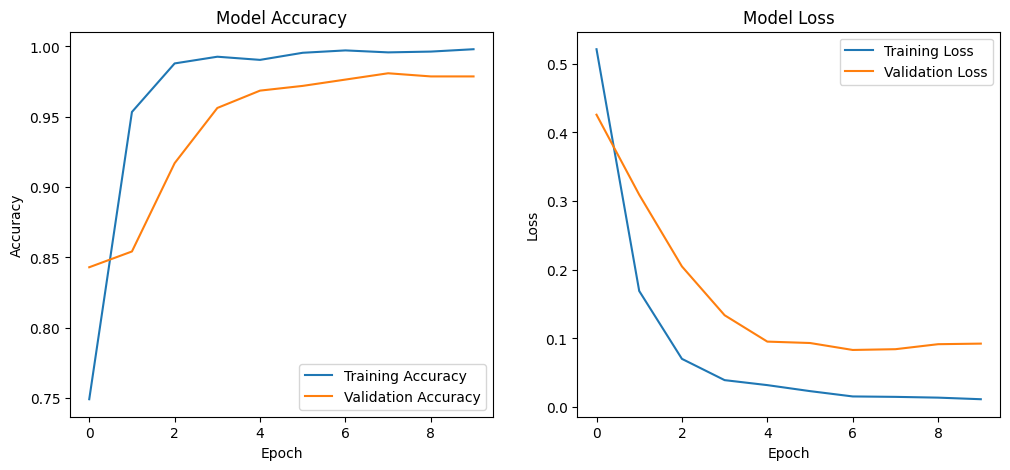

In [7]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

plt.show()

In [8]:
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", accuracy)

y_pred = (model.predict(X_test) >= 0.5).astype(int)

print(classification_report(
    y_test,
    y_pred,
    target_names=["Ham", "Spam"]
))

35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9821 - loss: 0.0754
Test Accuracy: 0.9820627570152283
35/35 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
              precision    recall  f1-score   support

         Ham       0.98      1.00      0.99       966
        Spam       0.98      0.88      0.93       149

    accuracy                           0.98      1115
   macro avg       0.98      0.94      0.96      1115
weighted avg       0.98      0.98      0.98      1115



In [9]:
messages = [
    "Congratulations! You won a free prize",
    "Hello, how are you today?",
    "Claim your free mobile recharge now"
]

message_vectors = vectorizer.transform(messages).toarray()

predictions = model.predict(message_vectors)

for message, prediction in zip(messages, predictions):
    confidence = prediction[0]

    result = "Spam" if confidence >= 0.5 else "Ham"

    confidence_score = (
        confidence if result == "Spam"
        else 1 - confidence
    )

    print("\nMessage:", message)
    print("Prediction:", result)
    print("Confidence:", round(float(confidence_score) * 100, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step

Message: Congratulations! You won a free prize
Prediction: Spam
Confidence: 99.93 %

Message: Hello, how are you today?
Prediction: Ham
Confidence: 99.76 %

Message: Claim your free mobile recharge now
Prediction: Spam
Confidence: 99.29 %
